In [11]:
import numpy as np
from scipy.io import wavfile
from scipy.signal import get_window
import scipy.fftpack as fft
import matplotlib.pyplot as plt

24000
2


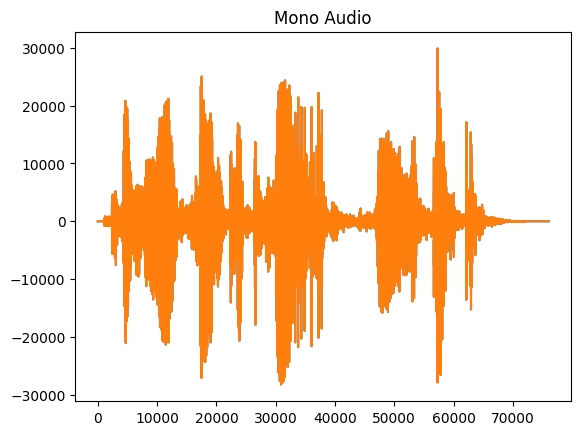

In [12]:
TRAIN_PATH = './sample.wav'
sr, audio = wavfile.read(TRAIN_PATH)

print(sr)
print(audio.ndim)
# ndim = 2 = stereo

plt.plot(audio)
plt.title("Mono Audio")
plt.show()

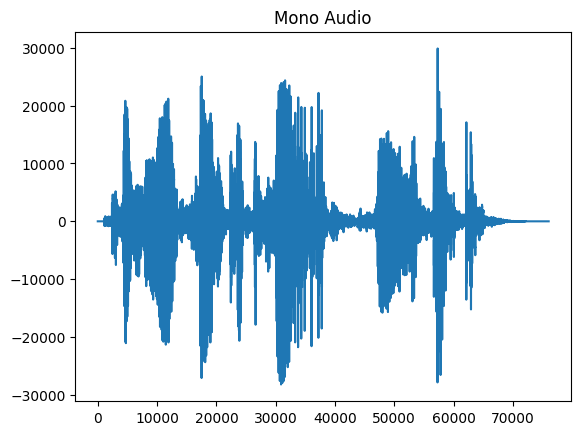

In [13]:
# convert stereo to mono
if audio.ndim > 1:
    audio = np.mean(audio, axis=1)
    
    
plt.plot(audio)
plt.title("Mono Audio")
plt.show()

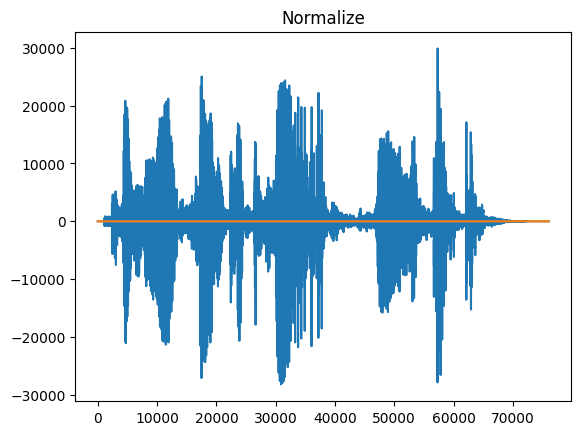

In [16]:
# Normalization
norm_audio = audio / np.max(np.abs(audio))
plt.plot(audio, label="Before norm")
plt.plot(norm_audio, label="After norm")
plt.title("Normalize")
plt.show()

In [27]:
# Framing
FFT_SIZE = 2048
HOP_SIZE = 15

pad_width = int(FFT_SIZE // 2) # idk why katanya int() here disuruh buat jaga2 salah type

pad_audio = np.pad(norm_audio, pad_width, mode='reflect') 
#     ABCDEFGHI
#   BAABCDEFGHIIH

 

HOP_LENGTH = int(np.round(sr * HOP_SIZE/1000))

frame_num = ((len(norm_audio) - FFT_SIZE) // HOP_LENGTH) + 1


frames = np.zeros((frame_num, FFT_SIZE))

for i in range(frame_num):
    start = i * HOP_LENGTH
    end = start + FFT_SIZE
    frames[i] = pad_audio[start:end]

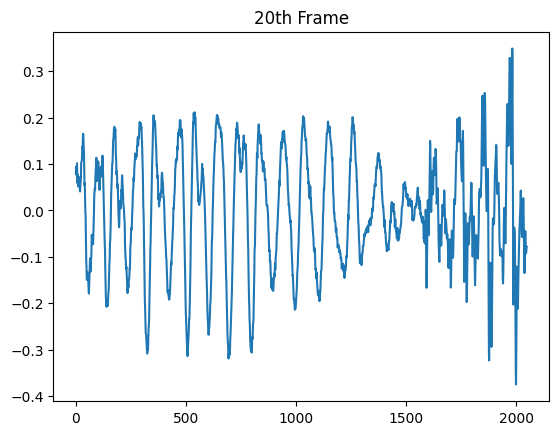

[ 0.07999464  0.0936841   0.08541688 ... -0.08702346 -0.07996117
 -0.07865582]


In [28]:
frameplot = frames[20]

plt.plot(frameplot)
plt.title("20th Frame")
plt.show()
print(frameplot)

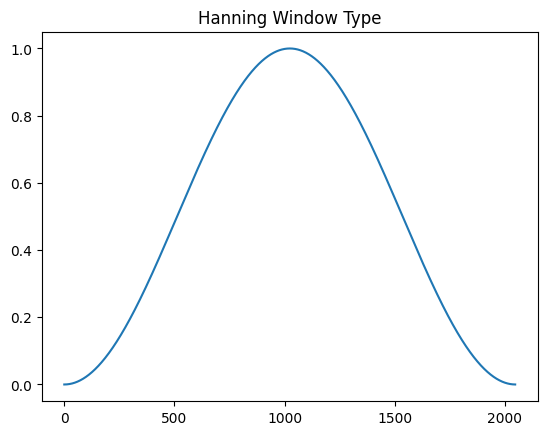

In [29]:
# Windowing
window_type = "hann"
window = get_window(window_type, FFT_SIZE, fftbins=True)

plt.plot(window)
plt.title("Hanning Window Type")

plt.show()

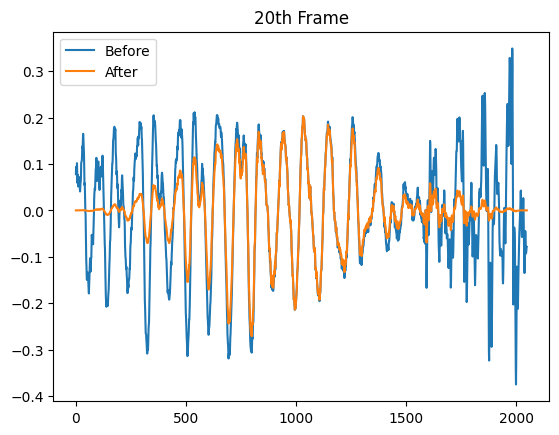

In [30]:
audio_win = frames * window

plt.plot(frames[20], label="Before")
plt.plot(audio_win[20], label="After")
plt.legend()
plt.title("20th Frame")
plt.show()

c:\Anaconda3\envs\speech_recognition\lib\site-packages\matplotlib\cbook\__init__.py:1335: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


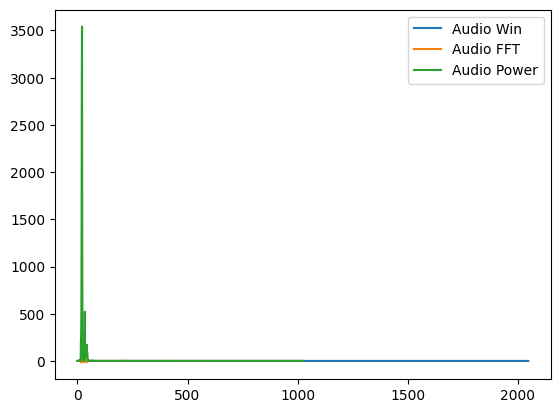

In [39]:
# FFT
audio_winT = np.transpose(audio_win)

audio_fft = np.empty(
    (1 + FFT_SIZE // 2, audio_winT.shape[1]),
    dtype=np.complex64
)

for i in range(audio_fft.shape[1]):
    fft_result = fft.fft(audio_winT[:, i])
    audio_fft[:, i] = fft_result[:audio_fft.shape[0]]
    
audio_fft = np.transpose(audio_fft)    

audio_pow = np.square(np.abs(audio_fft))

plt.plot(audio_win[20], label="Audio Win")
plt.plot(audio_fft[20], label="Audio FFT")
plt.plot(audio_pow[20], label="Audio Power")
plt.legend()
plt.show()